# Laboratorio #4 - Minería de datos (ISW-911)
**Universidad Técnica Nacional**

**Integrantes:**
- John Araya
- Ryan Vega 
- Juanda Gómez
- Emily Zuñiga

**Dataset:** Estadísticas Policiales 2025 - OIJ (Portal de Datos Abiertos del Poder Judicial)

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 6.4 MB/s eta 0:00:02
   ------------------- -------------------- 4.5/9.3 MB 12.5 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 12.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -------- ------------------------------- 1.8/8.2 MB 18.5 MB/s eta 0:00:01
   ------------------------------------ --- 7.6/8.2 MB 18.4 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 18.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------ --------------- 1.6/2.5 MB 15.6 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 10.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   --- ------------------------


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Lectura del dataset desde el repositorio público de GitHub
url = "https://raw.githubusercontent.com/JohnArayaE/lab4-mineria-datos/main/data/estadisticas_policiales_2025.csv"

# El archivo no trae fila de encabezados (header=None) y viene en latin-1 (tiene Ñ y tildes).
# 4 filas de 39,388 traen un campo de más (coma dentro de un valor); se descartan con
# on_bad_lines="warn" porque representan menos del 0.01% de los datos.
df = pd.read_csv(url, header=None, encoding="latin-1", on_bad_lines="warn")

df.shape

C:\Users\johnm\AppData\Local\Temp\ipykernel_43884\1636026625.py:10: ParserWarning: Skipping line 5186: expected 11 fields, saw 12
Skipping line 27800: expected 11 fields, saw 12
Skipping line 29674: expected 11 fields, saw 12
Skipping line 30702: expected 11 fields, saw 12

  df = pd.read_csv(url, header=None, encoding="latin-1", on_bad_lines="warn")


(39384, 11)

## Punto 4: Características principales del conjunto de datos

In [5]:
# Primeras filas del dataset
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Desconocido,NaN,Desconocido,SAN JOSE,SAN JOSE,HOSPITAL
1,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL
2,ASALTO,CANDADO CHINO,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,PUNTARENAS,PUNTARENAS,PUNTARENAS
3,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,TIBAS,SAN JUAN
4,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Desconocido,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL


In [6]:
# Tipos de datos y cantidad de valores no nulos por columna
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39384 entries, 0 to 39383
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       39384 non-null  object 
 1   1       39384 non-null  object 
 2   2       39384 non-null  object 
 3   3       39384 non-null  object 
 4   4       39384 non-null  object 
 5   5       39384 non-null  object 
 6   6       0 non-null      float64
 7   7       39384 non-null  object 
 8   8       39384 non-null  object 
 9   9       39384 non-null  object 
 10  10      39384 non-null  object 
dtypes: float64(1), object(10)
memory usage: 3.3+ MB


In [7]:
# Resumen estadístico (al ser columnas categóricas muestra: count, unique, top, freq)
df.describe(include="all")

,0,1,2,3,4,5,6,7,8,9,10
count,39384,39384,39384,39384,39384,39384,0.0,39384,39384,39384,39384
unique,6,39,365,4,79,4,NaN,79,8,85,385
top,HURTO,POR DESCUIDO,2025-11-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL
freq,12589,6789,182,16717,10076,33034,NaN,30656,15514,8684,1399
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# Cantidad de valores únicos por columna
df.nunique()

0       6
1      39
2     365
3       4
4      79
5       4
6       0
7      79
8       8
9      85
10    385
dtype: int64

**Observaciones:**
- El dataset tiene 39,384 registros y 11 columnas, sin fila de encabezados.
- 10 columnas son de tipo texto (object), incluida la fecha, y 1 es float64 porque viene completamente vacía.
- La columna 6 (género) no tiene ningún valor registrado.
- El delito más frecuente es HURTO (12,589 registros) y la provincia con más registros es SAN JOSE (15,514).
- No hay variables numéricas originales; todas son categóricas.

## Punto 5: Cambio de nombres de las columnas a español

In [9]:
# El archivo no trae encabezados, se asignan nombres en español según el contenido de cada columna
df.columns = [
    "delito",
    "subdelito",
    "fecha",
    "victima",
    "subvictima",
    "edad",
    "genero",
    "nacionalidad",
    "provincia",
    "canton",
    "distrito"
]

df.head()

,delito,subdelito,fecha,victima,subvictima,edad,genero,nacionalidad,provincia,canton,distrito
0,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Desconocido,NaN,Desconocido,SAN JOSE,SAN JOSE,HOSPITAL
1,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL
2,ASALTO,CANDADO CHINO,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,PUNTARENAS,PUNTARENAS,PUNTARENAS
3,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,TIBAS,SAN JUAN
4,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Desconocido,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL


## Punto 6: Valores nulos

En el dataset los valores faltantes no solo vienen vacíos (NaN): también se registran con el texto "Desconocido".
Antes de contar los nulos se eliminan los espacios sobrantes de los textos y se reemplaza "Desconocido" por NaN,
para que se contabilicen como valores faltantes.

In [10]:
# Columnas de texto
cols_texto = df.select_dtypes(include="object").columns

# Quitar espacios al inicio y al final de los textos
df[cols_texto] = df[cols_texto].apply(lambda col: col.str.strip())

# Reemplazar "Desconocido" (sin importar mayúsculas/minúsculas) por NaN
df[cols_texto] = df[cols_texto].replace(r"(?i)^desconocido$", np.nan, regex=True)

# Cantidad y porcentaje de nulos por columna
nulos = pd.DataFrame({
    "cantidad_nulos": df.isnull().sum(),
    "porcentaje_nulos": (df.isnull().mean() * 100).round(2)
})

nulos

,cantidad_nulos,porcentaje_nulos
delito,0,0.00
subdelito,26,0.07
fecha,0,0.00
victima,0,0.00
subvictima,0,0.00
edad,2443,6.20
genero,39384,100.00
nacionalidad,2286,5.80
provincia,2,0.01
canton,115,0.29


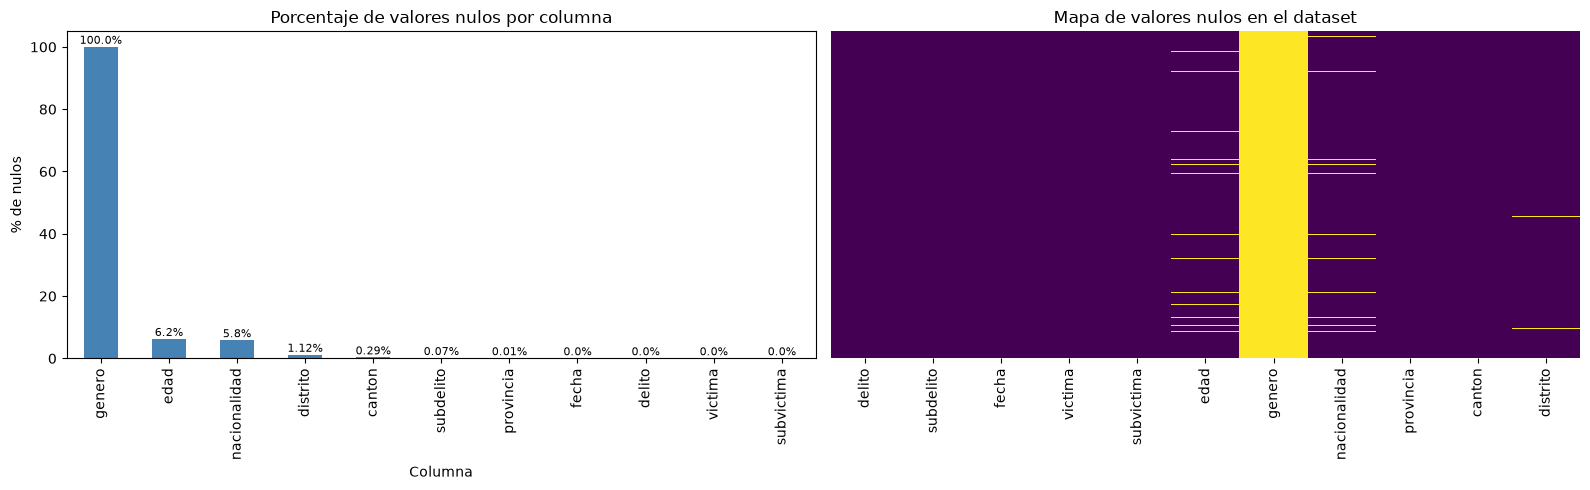

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: porcentaje de nulos por columna
nulos["porcentaje_nulos"].sort_values(ascending=False).plot(
    kind="bar", ax=axes[0], color="steelblue"
)
axes[0].set_title("Porcentaje de valores nulos por columna")
axes[0].set_ylabel("% de nulos")
axes[0].set_xlabel("Columna")
for i, v in enumerate(nulos["porcentaje_nulos"].sort_values(ascending=False)):
    axes[0].text(i, v + 1, f"{v}%", ha="center", fontsize=8)

# Gráfico 2: mapa de calor de nulos (cada línea clara es un valor faltante)
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
axes[1].set_title("Mapa de valores nulos en el dataset")

plt.tight_layout()
plt.show()

**Hallazgos de valores nulos:**
- **genero**: 100% nulos. La columna no aporta información, por lo que se eliminará.
- **edad** (6.2%) y **nacionalidad** (5.8%): son los que más nulos tienen después de género. En 1,830 registros ambas faltan a la vez (se ve en el mapa de calor), lo que indica registros donde no se tomaron los datos de la víctima.
- **distrito** (1.12%), **canton** (0.29%), **subdelito** (0.07%) y **provincia** (0.01%): porcentaje muy bajo de nulos.
- **delito, fecha, victima y subvictima**: no tienen valores nulos.